In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

In [3]:
df = sns.load_dataset("titanic")

print(df.head())
print(df.shape)

   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
(891, 15)


In [5]:
display(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [8]:
df["age"] = df["age"].fillna(df["age"].mean())
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])

df = df.drop("deck",axis=1)

In [9]:
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64

In [18]:
df["FamilySize"] = df["sibsp"] + df["parch"] + 1
df["AgeGroup"] = pd.cut(
    df["age"],
    bins=[0,12,18,60,100],
    labels=["Child","Teen","Adult","Senior"]
)

display(df[["age","FamilySize","AgeGroup"]].head())

,age,FamilySize,AgeGroup
0,22.0,2,Adult
1,38.0,2,Adult
2,26.0,1,Adult
3,35.0,2,Adult
4,35.0,1,Adult


In [29]:
df["sex"] = df["sex"].map({"male": 0, "female": 1})

display(df.head())

,survived,pclass,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,FamilySize,AgeGroup,embarked_C,embarked_Q,embarked_S
0,0,3,NaN,22.0,1,0,7.2500,Third,man,True,Southampton,no,False,2,Adult,0,0,1
1,1,1,NaN,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False,2,Adult,1,0,0
2,1,3,NaN,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True,1,Adult,0,0,1
3,1,1,NaN,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False,2,Adult,0,0,1
4,0,3,NaN,35.0,0,0,8.0500,Third,man,True,Southampton,no,True,1,Adult,0,0,1


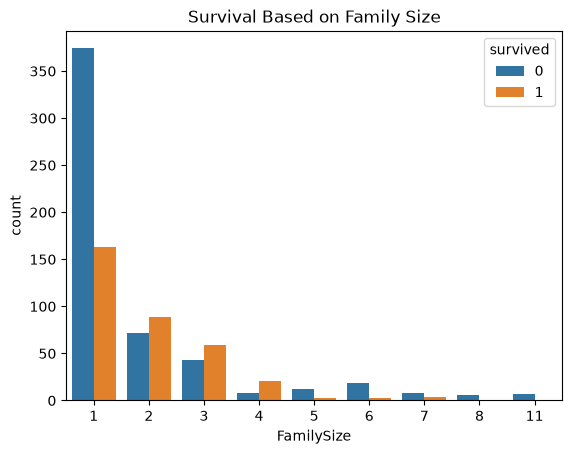

In [30]:
sns.countplot(data=df,x="FamilySize",hue="survived")
plt.title("Survival Based on Family Size")
plt.show()

In [32]:
df.shape

(891, 18)

In [33]:
display(df.head())

,survived,pclass,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,FamilySize,AgeGroup,embarked_C,embarked_Q,embarked_S
0,0,3,NaN,22.0,1,0,7.2500,Third,man,True,Southampton,no,False,2,Adult,0,0,1
1,1,1,NaN,38.0,1,0,71.2833,First,woman,False,Cherbourg,yes,False,2,Adult,1,0,0
2,1,3,NaN,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True,1,Adult,0,0,1
3,1,1,NaN,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False,2,Adult,0,0,1
4,0,3,NaN,35.0,0,0,8.0500,Third,man,True,Southampton,no,True,1,Adult,0,0,1
